# PlanetSEmu: Emulating Distributions of Planetary System Architectures

Code implementation accompanying the paper by Ky Potter, Lucas Brefka, Derek Bingham, Eric B. Ford, Kelly R. Moran, and David C. Stenning.


In [ ]:
# Run this once if the packages are not installed in your notebook kernel:
# %pip install "numpy>=1.26,<3" "pandas>=2.1,<3" "scipy>=1.11,<2" "matplotlib>=3.8,<4" "patsy>=0.5.6,<2" "statsmodels>=0.14.2,<0.15" "scikit-learn>=1.5,<1.9"


## Statistical target and factorization

The target distribution is

$$p(M_{\mathrm{obs}},\mathbf{Y}\mid X), \qquad \mathbf{Y}=(\xi,\mathcal{P},\Delta),$$

where $M_{\mathrm{obs}}$ is detected multiplicity, $\xi$ is period-normalized transit duration ratio, $\mathcal{P}$ is orbital period ratio, and $\Delta$ is spacing in mutual Hill radii.

The fitted model uses the structured factorization

$$p(M_{\mathrm{obs}}\mid X)\;p(\xi,\mathcal{P}\mid X,G)\;p(\Delta\mid X,G,\mathcal{P}),$$

with $G=g(M_{\mathrm{obs}})\in\{1,2,3+\}$. The code retains the source-data names `transMult`, `durationRatio`, `periodRatio`, and `mutualHill`; comments and equations use the paper notation.

## 1. Imports

In [1]:
# =============================================================================
# IMPORTS
# =============================================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional

from patsy import dmatrix, build_design_matrices
from scipy.stats import genpareto, kendalltau, spearmanr
from scipy.stats import t as student_t
from scipy.special import gammaln, logsumexp
from scipy.optimize import minimize_scalar
from statsmodels.regression.quantile_regression import QuantReg

from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from IPython.display import display
from inspect import signature


## 2. Data paths and loading

Only the two downloaded CSVs are required as external project files:

| CSV | Required columns |
| --- | --- |
| `flowiso_1e-9_adj_IO.csv` | `SIID`, `simvar`, `durationRatio`, `periodRatio`, `mutualHill` |
| `flowiso_1e-9_mult.csv` | `SIID`, `simvar`, `transMult` |

`simvar` is the positive simulator input X. The system table supplies detected multiplicity, and the pair table supplies neighboring-planet summaries. The existing join uses `(SIID, simvar)` and requires one system record per key. If repeated viewing geometries produce conflicting multiplicities under those keys, resolve the observation identifiers before merging; do not silently deduplicate.

Missing files, missing columns, duplicate system keys, and unmatched pairs produce an error. `DATA_DIR` is relative to the kernel's working directory unless you provide an absolute path. Optional environment variables can override the folder or individual files.


In [23]:
# Edit this folder to the location of your independently downloaded CSVs.
DATA_DIR = Path("/Users/kypotter/Desktop/External Projects/ExoEmu/ky_datafiles")

# DATA_DIR = Path(os.environ.get("EXOEMU_DATA_DIR", "data")).expanduser()
PAIR_DATA_PATH = Path(os.environ.get("EXOEMU_PAIR_DATA", str(DATA_DIR / "flowiso_1e-9_adj_IO.csv"))).expanduser()
MULTIPLICITY_DATA_PATH = Path(os.environ.get("EXOEMU_MULTIPLICITY_DATA", str(DATA_DIR / "flowiso_1e-9_mult.csv"))).expanduser()

# Enable after setting the paths. False allows inspection without loading data.
RUN_FULL_ANALYSIS = True
RUN_OPTIONAL_FIGURES = False
N_DEMO_INPUTS = 10
N_DEMO_DRAWS = 10

REQUIRED_PAIR_COLUMNS = {"SIID", "simvar", "durationRatio", "periodRatio", "mutualHill"}
REQUIRED_MULTIPLICITY_COLUMNS = {"SIID", "simvar", "transMult"}

def load_exoemu_data(pair_path=PAIR_DATA_PATH, multiplicity_path=MULTIPLICITY_DATA_PATH):
    """Load and validate the pair-level and system-level simulator outputs.

    `transMult` is the code-level name for the observed multiplicity M_obs used
    in the paper and thesis chapter. Pair-level summaries are merged with the
    system-level multiplicity using (`SIID`, `simvar`).
    """
    pair_path = Path(pair_path)
    multiplicity_path = Path(multiplicity_path)
    missing_files = [str(p) for p in (pair_path, multiplicity_path) if not p.exists()]
    if missing_files:
        raise FileNotFoundError(
            "Required ExoEmu data files were not found:\n  - "
            + "\n  - ".join(missing_files)
            + "\nSet EXOEMU_DATA_DIR or the individual EXOEMU_*_DATA environment variables."
        )

    pair_df = pd.read_csv(pair_path)
    multiplicity_df = pd.read_csv(multiplicity_path)

    missing_pair = REQUIRED_PAIR_COLUMNS.difference(pair_df.columns)
    missing_mult = REQUIRED_MULTIPLICITY_COLUMNS.difference(multiplicity_df.columns)
    if missing_pair or missing_mult:
        raise ValueError(
            f"Unexpected data schema. Missing pair columns={sorted(missing_pair)}; "
            f"missing multiplicity columns={sorted(missing_mult)}"
        )

    merged = pair_df.merge(
        multiplicity_df[["SIID", "simvar", "transMult"]],
        on=["SIID", "simvar"],
        how="left",
        validate="many_to_one",
    )
    if merged["transMult"].isna().any():
        n_missing = int(merged["transMult"].isna().sum())
        raise ValueError(f"Multiplicity was missing after the merge for {n_missing} pair rows.")

    return merged

if RUN_FULL_ANALYSIS:
    df = load_exoemu_data()
    display(df.head())
    print(f"Loaded {len(df):,} neighboring-planet-pair rows.")
else:
    print("Inspection mode. Set DATA_DIR and RUN_FULL_ANALYSIS=True to load data and fit.")


,SIID,simvar,periodRatio,mutualHill,durationRatio,a1,a2,e1,e2,i1,i2,m1,m2,b1,b2,argPeri1,argPeri2,longAscNode1,longAscNode2,transMult
0,201124.0,0.00001,1.310301,22.308075,0.921971,0.06252,0.07485,0.01774,0.06490,0.03766,0.07058,0.35209,0.16840,0.28488,0.28493,1.98839,2.04412,3.02524,0.35300,3.0
1,201124.0,0.00001,1.655273,35.775424,1.215621,0.07485,0.10475,0.06490,0.02719,0.07058,0.02265,0.16840,0.63684,0.28493,0.00447,2.04412,2.84342,0.35300,-0.21344,3.0
2,202273.0,0.00001,2.168906,50.661287,0.664733,0.06252,0.10475,0.01774,0.02719,0.03766,0.02265,0.35209,0.63684,0.35384,0.41227,1.98839,2.84342,3.02524,-0.21344,2.0
3,206322.0,0.00001,1.310301,22.308075,1.126095,0.06252,0.07485,0.01774,0.06490,0.03766,0.07058,0.35209,0.16840,0.05318,0.12753,1.98839,2.04412,3.02524,0.35300,3.0
4,206322.0,0.00001,1.655273,35.775424,0.954064,0.07485,0.10475,0.06490,0.02719,0.07058,0.02265,0.16840,0.63684,0.12753,0.31033,2.04412,2.84342,0.35300,-0.21344,3.0


Loaded 50,281 neighboring-planet-pair rows.


## 3. Model configuration

In [24]:
# =============================================================================
# MODEL CONFIGURATION
# =============================================================================
X_COL = "simvar"
K_COL = "transMult"
KGRP_COL = "k_grp"

Y_PR = "periodRatio"
Y_MH = "mutualHill"
Y_DR = "durationRatio"
Y_COLS = [Y_DR, Y_PR, Y_MH]

TAUS = np.array([
    0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.40,
    0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.98, 0.99, 0.995
])

SPLINE_DF_X = 7
SPLINE_DEGREE_X = 3

EPS = 1e-10

# EVT
TAU0 = 0.985
MIN_EXCEED = 30

# PIT cross-fitting
N_FOLDS_PIT = 5

# Calibration / copula bins
SIMVAR_BINS_CAL = 8
SIMVAR_BINS_COP = 6

# t-copula settings
TCOPULA_MIN_BIN_N = 300
TCOPULA_NU_BOUNDS = (2.5, 60.0)
TCOPULA_SHRINK = 0.02

RANDOM_SEED = 2025
RNG = np.random.default_rng(RANDOM_SEED)

PAPER_LABELS = {
    X_COL: r"$X$",
    KGRP_COL: r"$G$",
    Y_DR: r"$\xi$",
    Y_PR: r"$\mathcal{P}$",
    Y_MH: r"$\Delta_{\mathrm{Hill}}$",
}

## 4. Transformations and numerical utilities

In [25]:
# =============================================================================
# BASIC TRANSFORMS
# =============================================================================
def _safe_log(x: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    return np.log(np.clip(np.asarray(x), eps, None))

def _safe_exp(x: np.ndarray) -> np.ndarray:
    return np.exp(np.asarray(x))

# Keep PR and MH on log scale; DR on natural scale
def t_pr(y): return _safe_log(y)
def it_pr(z): return _safe_exp(z)
def t_mh(y): return _safe_log(y)
def it_mh(z): return _safe_exp(z)
def t_dr(y): return np.asarray(y)
def it_dr(z): return np.asarray(z)

TRANS = {Y_PR: t_pr, Y_MH: t_mh, Y_DR: t_dr}
INVTR = {Y_PR: it_pr, Y_MH: it_mh, Y_DR: it_dr}

In [26]:
# =============================================================================
# GENERAL UTILITIES
# =============================================================================
def _clip_u(u: np.ndarray) -> np.ndarray:
    return np.clip(np.asarray(u), EPS, 1 - EPS)

def rearrange_non_crossing(qvals: np.ndarray, taus: np.ndarray) -> np.ndarray:
    order = np.argsort(taus)
    inv = np.argsort(order)
    q_sorted = qvals[:, order]
    q_sorted = np.sort(q_sorted, axis=1)
    return q_sorted[:, inv]

def interp_quantile_from_taus(u: np.ndarray, qgrid_row: np.ndarray, taus: np.ndarray) -> np.ndarray:
    order = np.argsort(taus)
    t_sorted = taus[order]
    q_sorted = np.maximum.accumulate(qgrid_row[order])
    return np.interp(u, t_sorted, q_sorted, left=q_sorted[0], right=q_sorted[-1])

def interp_cdf_from_quantiles(y: np.ndarray, qgrid: np.ndarray, taus: np.ndarray) -> np.ndarray:
    n = y.shape[0]
    out = np.empty(n)
    order = np.argsort(taus)
    t_sorted = taus[order]

    for i in range(n):
        q = qgrid[i, order]
        q = np.maximum.accumulate(q)

        dq = np.diff(q)
        flat = np.isclose(dq, 0.0)
        if flat.any():
            q = q.copy()
            q[1:] += np.cumsum(flat) * EPS

        out[i] = float(np.interp(y[i], q, t_sorted, left=t_sorted[0], right=t_sorted[-1]))

    return np.clip(out, EPS, 1 - EPS)

def interp_cdf_from_quantiles_randomized(y: np.ndarray, qgrid: np.ndarray, taus: np.ndarray, rng=None) -> np.ndarray:
    rng = rng or np.random.default_rng(0)
    n = y.shape[0]
    out = np.empty(n)
    order = np.argsort(taus)
    t_sorted = taus[order]

    for i in range(n):
        q = qgrid[i, order]
        q = np.maximum.accumulate(q)

        yi = y[i]
        if yi <= q[0]:
            out[i] = t_sorted[0]
            continue
        if yi >= q[-1]:
            out[i] = t_sorted[-1]
            continue

        j = np.searchsorted(q, yi, side="right") - 1
        j = int(np.clip(j, 0, len(q) - 2))

        frac = (yi - q[j]) / max(q[j + 1] - q[j], 1e-12)
        u_det = t_sorted[j] + frac * (t_sorted[j + 1] - t_sorted[j])

        # jitter = (t_sorted[j + 1] - t_sorted[j]) * (rng.random() - 0.5) * 0.15
        jitter = (t_sorted[j + 1] - t_sorted[j]) * (rng.random() - 0.5) * 0.6
        out[i] = u_det + jitter

    return np.clip(out, EPS, 1 - EPS)

def quantile_at_tau_from_grid(Q: np.ndarray, taus: np.ndarray, tau: float) -> np.ndarray:
    order = np.argsort(taus)
    t = taus[order]
    out = np.empty(Q.shape[0])
    for i in range(Q.shape[0]):
        q = np.maximum.accumulate(Q[i, order])
        out[i] = np.interp(tau, t, q, left=q[0], right=q[-1])
    return out

def kendall_tau_matrix(U: np.ndarray, names: List[str]) -> pd.DataFrame:
    k = U.shape[1]
    tau = np.eye(k)
    for i in range(k):
        for j in range(i + 1, k):
            tau[i, j] = tau[j, i] = kendalltau(U[:, i], U[:, j]).correlation
    return pd.DataFrame(tau, index=names, columns=names)

def sample_from_qgrid_no_evt(u: float, qrow: np.ndarray, taus: np.ndarray) -> float:
    return float(interp_quantile_from_taus(np.array([u]), qrow, taus)[0])

## 5. Coarsened multiplicity groups

In [27]:
# =============================================================================
# k GROUPING
# =============================================================================
def make_k_group(k: np.ndarray, scheme: str = "1-2-3p") -> np.ndarray:
    k = np.asarray(k).astype(int)
    if scheme == "1-2-3p":
        return np.where(k <= 1, 1, np.where(k == 2, 2, 3))
    elif scheme == "1-2-3-4p":
        return np.where(k <= 1, 1, np.where(k == 2, 2, np.where(k == 3, 3, 4)))
    else:
        raise ValueError(f"Unknown scheme={scheme}")

def add_k_group_column(df: pd.DataFrame, k_col: str = K_COL, scheme: str = "1-2-3p") -> pd.DataFrame:
    dfo = df.copy()
    dfo[KGRP_COL] = make_k_group(dfo[k_col].to_numpy(), scheme=scheme)
    cats = [1, 2, 3] if scheme == "1-2-3p" else [1, 2, 3, 4]
    dfo[KGRP_COL] = pd.Categorical(dfo[KGRP_COL], categories=cats, ordered=True)
    return dfo

## 6. Calibrated multiplicity model

In [28]:
# =============================================================================
# transMult model
# =============================================================================
@dataclass
class TransMultModel:
    pipeline: Pipeline
    classes_: np.ndarray
    temperature_: float = 1.0

    def _logits(self, simvar: np.ndarray) -> np.ndarray:
        x = np.log(np.asarray(simvar).reshape(-1, 1))
        spline = self.pipeline.named_steps["spline"]
        clf = self.pipeline.named_steps["clf"]
        F = spline.transform(x)
        z = clf.decision_function(F)
        if z.ndim == 1:
            z = np.column_stack([np.zeros_like(z), z])
        return z

    def predict_proba(self, simvar: np.ndarray) -> np.ndarray:
        z = self._logits(simvar) / float(self.temperature_)
        z = z - logsumexp(z, axis=1, keepdims=True)
        return np.exp(z)

    def sample(self, simvar: np.ndarray, n_draws: int = 1, rng=None) -> np.ndarray:
        rng = rng or np.random.default_rng()
        p = self.predict_proba(simvar)
        n = p.shape[0]
        out = np.empty((n_draws, n), dtype=int)
        cdf = np.cumsum(p, axis=1)
        for d in range(n_draws):
            u = rng.random(n)
            idx = (u[:, None] <= cdf).argmax(axis=1)
            out[d, :] = self.classes_[idx].astype(int)
        return out

def fit_transmult_model(df: pd.DataFrame,
                        x_col: str = X_COL,
                        k_col: str = K_COL,
                        max_k: int = 12,
                        spline_knots: int = 10,
                        test_size: float = 0.2,
                        seed: int = 2025,
                        C: float = 2.0,
                        max_iter: int = 4000) -> TransMultModel:
    dfi = df[[x_col, k_col]].dropna().copy()
    dfi = dfi[(dfi[k_col] >= 1) & (dfi[k_col] <= max_k)].copy()

    X = np.log(dfi[x_col].to_numpy()).reshape(-1, 1)
    y = dfi[k_col].astype(int).to_numpy()

    Xtr, Xva, ytr, yva = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )

    pipe = Pipeline([
        ("spline", SplineTransformer(n_knots=spline_knots, degree=3, include_bias=True)),
        ("clf", LogisticRegression(
            **({"multi_class": "multinomial"} if "multi_class" in signature(LogisticRegression).parameters else {}),
            solver="lbfgs",
            C=C,
            max_iter=max_iter
        ))
    ])
    pipe.fit(Xtr, ytr)

    spline = pipe.named_steps["spline"]
    clf = pipe.named_steps["clf"]
    Fva = spline.transform(Xva)
    logits = clf.decision_function(Fva)
    if logits.ndim == 1:
        logits = np.column_stack([np.zeros_like(logits), logits])
    classes_ = clf.classes_

    def nll(T):
        z = logits / T
        z = z - logsumexp(z, axis=1, keepdims=True)
        p = np.exp(z)
        y_idx = np.searchsorted(classes_, yva)
        return -np.mean(np.log(np.clip(p[np.arange(len(yva)), y_idx], EPS, 1.0)))

    Ts = np.linspace(0.5, 3.0, 60)
    vals = np.array([nll(T) for T in Ts])
    T0 = float(Ts[np.argmin(vals)])

    Ts2 = np.linspace(max(0.2, T0 - 0.6), T0 + 0.6, 80)
    vals2 = np.array([nll(T) for T in Ts2])
    T_hat = float(Ts2[np.argmin(vals2)])

    return TransMultModel(pipeline=pipe, classes_=classes_, temperature_=T_hat)

def plot_transmult_calibration(df: pd.DataFrame,
                               tm: TransMultModel,
                               x_col: str = X_COL,
                               k_col: str = K_COL,
                               max_k: int = 12,
                               n_bins: int = 8):
    dfi = df[[x_col, k_col]].dropna().copy()
    dfi = dfi[(dfi[k_col] >= 1) & (dfi[k_col] <= max_k)].copy()

    x = dfi[x_col].to_numpy()
    k = dfi[k_col].astype(int).to_numpy()
    edges = np.quantile(x, np.linspace(0, 1, n_bins + 1))
    ks = np.arange(1, max_k + 1)

    for b in range(n_bins):
        lo, hi = edges[b], edges[b + 1]
        m = (x >= lo) & (x <= hi) if b == n_bins - 1 else (x >= lo) & (x < hi)
        if m.sum() < 30:
            continue

        p = tm.predict_proba(x[m])
        p_full = np.zeros((p.shape[0], len(ks)))
        for j, kk in enumerate(tm.classes_):
            if 1 <= kk <= max_k:
                p_full[:, kk - 1] = p[:, j]
        pred = p_full.mean(axis=0)
        obs = np.array([(k[m] == kk).mean() for kk in ks])

        plt.figure(figsize=(10, 3))
        plt.bar(ks - 0.2, obs, width=0.4, alpha=0.8, label="Observed")
        plt.bar(ks + 0.2, pred, width=0.4, alpha=0.7, label="Predicted")
        plt.title(f"transMult calibration | {x_col} in [{lo:.3g}, {hi:.3g}] (n={m.sum()})")
        plt.xlabel("transMult")
        plt.ylabel("frequency")
        plt.ylim(0, max(obs.max(), pred.max()) * 1.15 + 1e-6)
        plt.legend()
        plt.tight_layout()

## 7. Conditional marginal quantile models

In [29]:
# =============================================================================
# Quantile marginals for PR and DR
# =============================================================================
@dataclass
class QuantileMarginal:
    taus: np.ndarray
    models: Dict[float, object]
    design_info: object
    formula: str
    k_levels: List[int]
    y_name: str
    lbx: float
    ubx: float

def make_design_info(df: pd.DataFrame, formula: str):
    X = dmatrix(formula, df, return_type="dataframe")
    return np.asarray(X), X.design_info

def build_design_from_info(df_new: pd.DataFrame, design_info) -> np.ndarray:
    Xn = build_design_matrices([design_info], df_new)[0]
    return np.asarray(Xn)

def fit_marginal_qr(df: pd.DataFrame,
                    y_name: str,
                    taus: np.ndarray,
                    x_col: str = X_COL,
                    kgrp_col: str = KGRP_COL,
                    spline_df_x: int = SPLINE_DF_X,
                    spline_degree_x: int = SPLINE_DEGREE_X,
                    lbx: Optional[float] = None,
                    ubx: Optional[float] = None) -> QuantileMarginal:
    dfi = df[[x_col, kgrp_col, y_name]].dropna().copy()
    dfi["_logx"] = np.log(dfi[x_col].to_numpy())
    dfi["_kg"] = dfi[kgrp_col]
    y_t = TRANS[y_name](dfi[y_name].to_numpy())

    if lbx is None:
        lbx = float(dfi["_logx"].min() - 1e-6)
    if ubx is None:
        ubx = float(dfi["_logx"].max() + 1e-6)

    base = (
        f"bs(_logx, df={spline_df_x}, degree={spline_degree_x}, include_intercept=True, "
        f"lower_bound={lbx}, upper_bound={ubx})"
    )
    formula = f"{base} * C(_kg)"

    X, design_info = make_design_info(dfi, formula)
    models = {float(t): QuantReg(y_t, X).fit(q=float(t)) for t in taus}
    k_levels = list(dfi["_kg"].cat.categories)

    return QuantileMarginal(
        taus=taus,
        models=models,
        design_info=design_info,
        formula=formula,
        k_levels=[int(v) for v in k_levels],
        y_name=y_name,
        lbx=float(lbx),
        ubx=float(ubx)
    )

def predict_quantile_grid(qm: QuantileMarginal, simvar: np.ndarray, k_grp: np.ndarray) -> np.ndarray:
    logx = np.log(np.asarray(simvar))
    logx = np.clip(logx, qm.lbx, qm.ubx)

    df_new = pd.DataFrame({
        "_logx": logx,
        "_kg": pd.Categorical(k_grp, categories=qm.k_levels, ordered=True)
    })
    Xn = build_design_from_info(df_new, qm.design_info)
    preds = [qm.models[float(t)].predict(Xn) for t in qm.taus]
    Q = np.column_stack(preds)
    return rearrange_non_crossing(Q, qm.taus)

## 8. Conditional Hill-spacing model

In [30]:
# =============================================================================
# Conditional MH model
# =============================================================================
@dataclass
class MHConditionalQR:
    taus: np.ndarray
    models: Dict[float, object]
    design_info: object
    formula: str
    k_levels: List[int]
    lbx: float
    ubx: float
    lbpr: float
    ubpr: float

def fit_mh_conditional_qr(df: pd.DataFrame,
                          taus: np.ndarray,
                          x_col: str = X_COL,
                          kgrp_col: str = KGRP_COL,
                          pr_col: str = Y_PR,
                          mh_col: str = Y_MH,
                          spline_df_x: int = 6,
                          spline_df_pr: int = 6,
                          spline_degree: int = 3,
                          lbx: Optional[float] = None,
                          ubx: Optional[float] = None,
                          lbpr: Optional[float] = None,
                          ubpr: Optional[float] = None) -> MHConditionalQR:
    dfi = df[[x_col, kgrp_col, pr_col, mh_col]].dropna().copy()
    dfi["_logx"] = np.log(dfi[x_col].to_numpy())
    dfi["_logpr"] = _safe_log(dfi[pr_col].to_numpy())
    dfi["_kg"] = dfi[kgrp_col]
    y_t = _safe_log(dfi[mh_col].to_numpy())

    if lbx is None:
        lbx = float(dfi["_logx"].min() - 1e-6)
    if ubx is None:
        ubx = float(dfi["_logx"].max() + 1e-6)
    if lbpr is None:
        lbpr = float(dfi["_logpr"].min() - 1e-6)
    if ubpr is None:
        ubpr = float(dfi["_logpr"].max() + 1e-6)

    fx = (
        f"bs(_logx, df={spline_df_x}, degree={spline_degree}, include_intercept=True, "
        f"lower_bound={lbx}, upper_bound={ubx})"
    )
    fpr = (
        f"bs(_logpr, df={spline_df_pr}, degree={spline_degree}, include_intercept=True, "
        f"lower_bound={lbpr}, upper_bound={ubpr})"
    )
    formula = f"{fx} * C(_kg) + {fpr} * C(_kg) + {fx}:{fpr}"

    X, design_info = make_design_info(dfi, formula)
    models = {float(t): QuantReg(y_t, X).fit(q=float(t)) for t in taus}
    k_levels = list(dfi["_kg"].cat.categories)

    return MHConditionalQR(
        taus=taus,
        models=models,
        design_info=design_info,
        formula=formula,
        k_levels=[int(v) for v in k_levels],
        lbx=float(lbx),
        ubx=float(ubx),
        lbpr=float(lbpr),
        ubpr=float(ubpr)
    )

def predict_mh_quantile_grid(mh_qr: MHConditionalQR,
                             simvar: np.ndarray,
                             k_grp: np.ndarray,
                             pr: np.ndarray) -> np.ndarray:
    logx = np.log(np.asarray(simvar))
    logpr = _safe_log(np.asarray(pr))

    logx = np.clip(logx, mh_qr.lbx, mh_qr.ubx)
    logpr = np.clip(logpr, mh_qr.lbpr, mh_qr.ubpr)

    df_new = pd.DataFrame({
        "_logx": logx,
        "_logpr": logpr,
        "_kg": pd.Categorical(k_grp, categories=mh_qr.k_levels, ordered=True)
    })
    Xn = build_design_from_info(df_new, mh_qr.design_info)
    preds = [mh_qr.models[float(t)].predict(Xn) for t in mh_qr.taus]
    Q = np.column_stack(preds)
    return rearrange_non_crossing(Q, mh_qr.taus)

## 9. Probability integral transforms and calibration

In [31]:
# =============================================================================
# PIT helpers
# =============================================================================
def pit_for_qr(df: pd.DataFrame, qm: QuantileMarginal, y_name: str):
    dfi = df[[X_COL, KGRP_COL, y_name]].dropna().copy()
    x = dfi[X_COL].to_numpy()
    k = dfi[KGRP_COL].astype(int).to_numpy()
    Q = predict_quantile_grid(qm, x, k)
    y_t = TRANS[y_name](dfi[y_name].to_numpy())
    u = interp_cdf_from_quantiles_randomized(y_t, Q, qm.taus, rng=np.random.default_rng(123))
    return u, dfi.index

def pit_for_mh_cond(df: pd.DataFrame, mh_cond: MHConditionalQR):
    dfi = df[[X_COL, KGRP_COL, Y_PR, Y_MH]].dropna().copy()

    x = dfi[X_COL].to_numpy()
    k = dfi[KGRP_COL].astype(int).to_numpy()
    pr = dfi[Y_PR].to_numpy()

    Q = predict_mh_quantile_grid(mh_cond, x, k, pr)
    y_t = t_mh(dfi[Y_MH].to_numpy())
    u = interp_cdf_from_quantiles_randomized(y_t, Q, mh_cond.taus, rng=np.random.default_rng(123))

    return u, dfi.index

In [32]:
# =============================================================================
# PIT calibrator
# =============================================================================
@dataclass
class PITCalibrator:
    edges: np.ndarray
    k_levels: List[int]
    var_names: List[str]
    inv_maps_: Dict[Tuple[str, int, int], Tuple[np.ndarray, np.ndarray]] = field(default_factory=dict)

    def _bin_id(self, x: float) -> int:
        if self.edges is None or len(self.edges) == 0:
            return 0
        return int(np.clip(np.searchsorted(self.edges, x, side="right"), 0, len(self.edges)))

    def fit_from_oof(self, df_oof: pd.DataFrame, x_col: str, k_col: str, u_cols: Dict[str, str],
                     min_n: int = 140):
        for var in self.var_names:
            ucol = u_cols[var]
            for k in self.k_levels:
                mk = (df_oof[k_col].astype(int).to_numpy() == int(k))
                if mk.sum() < min_n:
                    continue

                xs = df_oof.loc[mk, x_col].to_numpy()
                us = np.clip(df_oof.loc[mk, ucol].to_numpy(), EPS, 1 - EPS)

                if self.edges is None or len(self.edges) == 0:
                    bin_ids = np.zeros_like(xs, dtype=int)
                    bins = [0]
                else:
                    bin_ids = np.clip(np.searchsorted(self.edges, xs, side="right"), 0, len(self.edges))
                    bins = np.unique(bin_ids)

                for b in bins:
                    m = (bin_ids == b)
                    if m.sum() < min_n:
                        continue
                    u_sorted = np.sort(us[m])
                    n = len(u_sorted)
                    cal = np.arange(1, n + 1) / (n + 1.0)
                    self.inv_maps_[(var, int(k), int(b))] = (u_sorted, cal)
        return self

    def inverse(self, u_cal: float, var: str, x: float, k: int) -> float:
        b = self._bin_id(x)
        key = (var, int(k), int(b))
        if key not in self.inv_maps_:
            key0 = (var, int(k), 0)
            if key0 not in self.inv_maps_:
                return float(np.clip(u_cal, EPS, 1 - EPS))
            key = key0

        u_sorted, cal_sorted = self.inv_maps_[key]
        u_raw = np.interp(u_cal, cal_sorted, u_sorted, left=u_sorted[0], right=u_sorted[-1])
        return float(np.clip(u_raw, EPS, 1 - EPS))

## 10. Student-t copula

In [33]:
# =============================================================================
# t-copula bank for calibrated (DR, PR)
# =============================================================================
def _t_copula_negloglik(U: np.ndarray, R: np.ndarray, nu: float) -> float:
    U = np.clip(U, EPS, 1 - EPS)
    Z = student_t.ppf(U, df=nu)
    n, k = Z.shape

    L = np.linalg.cholesky(R)
    LinvZ = Z @ np.linalg.inv(L).T
    Q = np.sum(LinvZ ** 2, axis=1)
    logdetR = 2.0 * np.sum(np.log(np.diag(L)))

    ll_mv = (
        gammaln((nu + k) / 2) - gammaln(nu / 2)
        - (k / 2) * np.log(nu * np.pi)
        - 0.5 * logdetR
        - ((nu + k) / 2) * np.log1p(Q / nu)
    )

    ll_uv = (
        gammaln((nu + 1) / 2) - gammaln(nu / 2)
        - 0.5 * np.log(nu * np.pi)
        - ((nu + 1) / 2) * np.log1p((Z ** 2) / nu)
    )
    ll_uv_sum = np.sum(ll_uv, axis=1)

    return float(-np.sum(ll_mv - ll_uv_sum))

def fit_t_copula(U: np.ndarray,
                 nu_bounds: Tuple[float, float] = TCOPULA_NU_BOUNDS,
                 shrink: float = TCOPULA_SHRINK) -> Dict[str, np.ndarray]:
    U = np.asarray(U)

    def objective(nu):
        Z = student_t.ppf(np.clip(U, EPS, 1 - EPS), df=nu)
        R = np.corrcoef(Z.T)
        R = (1.0 - shrink) * R + shrink * np.eye(R.shape[0])
        return _t_copula_negloglik(U, R, nu)

    res = minimize_scalar(objective, bounds=nu_bounds, method="bounded")
    nu_hat = float(res.x)

    Z = student_t.ppf(np.clip(U, EPS, 1 - EPS), df=nu_hat)
    R_hat = np.corrcoef(Z.T)
    R_hat = (1.0 - shrink) * R_hat + shrink * np.eye(R_hat.shape[0])

    return {"nu": nu_hat, "corr": R_hat}

@dataclass
class TCopulaSpec:
    nu: float
    corr: np.ndarray
    tau_emp: float
    n_fit: int

@dataclass
class TCopulaBank:
    groups: List[Tuple[int, int]]
    simvar_bins: int
    x_edges: Optional[np.ndarray]
    specs: Dict[Tuple[int, int], TCopulaSpec] = field(default_factory=dict)

    def pick_key(self, x_val: float, k_val: int) -> Tuple[int, int]:
        g_idx = None
        for i, (lo, hi) in enumerate(self.groups):
            if lo <= k_val <= hi:
                g_idx = i
                break
        if g_idx is None:
            g_idx = len(self.groups) - 1

        if self.simvar_bins <= 1 or self.x_edges is None:
            b_idx = 0
        else:
            b_idx = int(np.searchsorted(self.x_edges, x_val, side="right"))
            b_idx = int(np.clip(b_idx, 0, self.simvar_bins - 1))
        return g_idx, b_idx

    def sampler_for(self, x_val: float, k_val: int):
        key = self.pick_key(x_val, k_val)
        spec = self.specs[key]
        L = np.linalg.cholesky(spec.corr)
        nu = spec.nu

        def sampler(n_draws: int, rng=None) -> np.ndarray:
            rng = rng or np.random.default_rng()
            k = L.shape[0]
            Z = rng.standard_normal(size=(k, n_draws))
            Z = L @ Z
            s = np.sqrt(rng.chisquare(nu, size=(1, n_draws)) / nu)
            T = Z / s
            U = student_t.cdf(T, df=nu)
            return _clip_u(U)

        return sampler

def fit_tcopula_bank(df_u: pd.DataFrame,
                     groups: List[Tuple[int, int]],
                     simvar_bins: int = SIMVAR_BINS_COP,
                     min_bin_n: int = TCOPULA_MIN_BIN_N,
                     nu_bounds: Tuple[float, float] = TCOPULA_NU_BOUNDS,
                     shrink: float = TCOPULA_SHRINK,
                     verbose: bool = True) -> TCopulaBank:
    dfi = df_u.dropna().copy()
    x = dfi[X_COL].to_numpy()
    k = dfi[KGRP_COL].astype(int).to_numpy()
    U = dfi[["u_dr_cal", "u_pr_cal"]].to_numpy()

    if simvar_bins > 1:
        edges = np.quantile(x, np.linspace(0, 1, simvar_bins + 1))
        x_edges = edges[1:-1]
    else:
        x_edges = None

    tau_all = kendalltau(U[:, 0], U[:, 1]).correlation
    if np.isnan(tau_all):
        tau_all = 0.0
    fit_all = fit_t_copula(U, nu_bounds=nu_bounds, shrink=shrink)
    global_spec = TCopulaSpec(
        nu=float(fit_all["nu"]),
        corr=np.asarray(fit_all["corr"]),
        tau_emp=float(tau_all),
        n_fit=len(U)
    )

    specs: Dict[Tuple[int, int], TCopulaSpec] = {}

    for gi, (klo, khi) in enumerate(groups):
        mg = (k >= klo) & (k <= khi)
        n_g = int(mg.sum())

        if n_g == 0:
            for bi in range(max(1, simvar_bins)):
                specs[(gi, bi)] = global_spec
            continue

        Ug = U[mg, :]
        xg = x[mg]

        tau_g = kendalltau(Ug[:, 0], Ug[:, 1]).correlation
        if np.isnan(tau_g):
            tau_g = 0.0

        if n_g < min_bin_n:
            group_spec = global_spec
        else:
            fit_g = fit_t_copula(Ug, nu_bounds=nu_bounds, shrink=shrink)
            group_spec = TCopulaSpec(
                nu=float(fit_g["nu"]),
                corr=np.asarray(fit_g["corr"]),
                tau_emp=float(tau_g),
                n_fit=n_g
            )

        if simvar_bins <= 1:
            specs[(gi, 0)] = group_spec
            continue

        bin_ids = np.clip(np.searchsorted(x_edges, xg, side="right"), 0, simvar_bins - 1)
        counts = [int((bin_ids == bi).sum()) for bi in range(simvar_bins)]
        if verbose:
            print(f"[tcop] group gi={gi} n={n_g} per-bin counts: {counts} | tau_g={tau_g:.3f} | nu_g={group_spec.nu:.3f}")

        for bi in range(simvar_bins):
            mb = (bin_ids == bi)
            nb = int(mb.sum())
            if nb < min_bin_n:
                specs[(gi, bi)] = group_spec
                continue

            Ub = Ug[mb, :]
            tau_b = kendalltau(Ub[:, 0], Ub[:, 1]).correlation
            if np.isnan(tau_b):
                tau_b = 0.0

            fit_b = fit_t_copula(Ub, nu_bounds=nu_bounds, shrink=shrink)
            specs[(gi, bi)] = TCopulaSpec(
                nu=float(fit_b["nu"]),
                corr=np.asarray(fit_b["corr"]),
                tau_emp=float(tau_b),
                n_fit=nb
            )

    for gi in range(len(groups)):
        for bi in range(max(1, simvar_bins)):
            specs.setdefault((gi, bi), global_spec)

    return TCopulaBank(groups=groups, simvar_bins=simvar_bins, x_edges=x_edges, specs=specs)

## 11. Upper-tail refinement

In [34]:
# =============================================================================
# EVT tails for BOTH durationRatio and periodRatio
# =============================================================================
@dataclass
class TailBank:
    groups: List[Tuple[int, int]]
    tau0: float
    params: Dict[Tuple[str, int], Tuple[float, float]]

def fit_gpd_tails_by_group(df: pd.DataFrame,
                           pr_marg: QuantileMarginal,
                           dr_marg: QuantileMarginal,
                           groups: List[Tuple[int, int]],
                           tau0: float = TAU0,
                           min_exceed: int = MIN_EXCEED) -> TailBank:
    dfi = df[[X_COL, KGRP_COL, Y_PR, Y_DR]].dropna().copy()
    x = dfi[X_COL].to_numpy()
    k = dfi[KGRP_COL].astype(int).to_numpy()

    params: Dict[Tuple[str, int], Tuple[float, float]] = {}

    y_dr = t_dr(dfi[Y_DR].to_numpy())
    Q_dr = predict_quantile_grid(dr_marg, x, k)
    q0_dr = quantile_at_tau_from_grid(Q_dr, dr_marg.taus, tau0)

    y_pr = t_pr(dfi[Y_PR].to_numpy())
    Q_pr = predict_quantile_grid(pr_marg, x, k)
    q0_pr = quantile_at_tau_from_grid(Q_pr, pr_marg.taus, tau0)

    for gi, (klo, khi) in enumerate(groups):
        mg = (k >= klo) & (k <= khi)

        exc = (y_dr[mg] - q0_dr[mg])
        exc = exc[exc > 0]
        if exc.size < min_exceed:
            exc_all = (y_dr - q0_dr)
            exc_all = exc_all[exc_all > 0]
            if exc_all.size >= 15:
                c, _, scale = genpareto.fit(exc_all, floc=0.0)
            else:
                c, scale = 0.0, float(np.std(y_dr) * 0.5 + 1e-6)
        else:
            c, _, scale = genpareto.fit(exc, floc=0.0)
        params[(Y_DR, gi)] = (float(c), float(scale))

        exc = (y_pr[mg] - q0_pr[mg])
        exc = exc[exc > 0]
        if exc.size < min_exceed:
            exc_all = (y_pr - q0_pr)
            exc_all = exc_all[exc_all > 0]
            if exc_all.size >= 15:
                c, _, scale = genpareto.fit(exc_all, floc=0.0)
            else:
                c, scale = 0.0, float(np.std(y_pr) * 0.5 + 1e-6)
        else:
            c, _, scale = genpareto.fit(exc, floc=0.0)
        params[(Y_PR, gi)] = (float(c), float(scale))

    return TailBank(groups=groups, tau0=float(tau0), params=params)

In [35]:
# =============================================================================
# EVT inverse helper
# =============================================================================
def _sample_from_qgrid_evt(u: float, qrow: np.ndarray, taus: np.ndarray, tau0: float,
                           xi: float, beta: float) -> float:
    if u <= tau0:
        return float(interp_quantile_from_taus(np.array([u]), qrow, taus)[0])

    ut = (u - tau0) / (1 - tau0)
    ut = float(np.clip(ut, EPS, 1 - EPS))

    if np.isclose(xi, 0.0):
        exc = -beta * np.log(1 - ut)
    else:
        exc = beta / xi * ((1 - ut) ** (-xi) - 1)

    q_tau0 = float(interp_quantile_from_taus(np.array([tau0]), qrow, taus)[0])
    return q_tau0 + exc

## 12. Conditional sampling

In [36]:
# =============================================================================
# Simulation
# =============================================================================
def simulate_structural(simvar_new: np.ndarray,
                        trans_model: TransMultModel,
                        pr_marg: QuantileMarginal,
                        dr_marg: QuantileMarginal,
                        mh_cond: MHConditionalQR,
                        copula_drpr: TCopulaBank,
                        tails: TailBank,
                        pitcal: PITCalibrator,
                        groups: List[Tuple[int, int]],
                        k_scheme: str = "1-2-3p",
                        n_draws: int = 1,
                        rng=None) -> Dict[str, np.ndarray]:
    rng = rng or np.random.default_rng()
    simvar_new = np.asarray(simvar_new).reshape(-1)
    n = simvar_new.size

    k_draws = trans_model.sample(simvar_new, n_draws=n_draws, rng=rng)

    out = {
        "transMult": k_draws.copy(),
        Y_PR: np.empty((n_draws, n), float),
        Y_DR: np.empty((n_draws, n), float),
        Y_MH: np.empty((n_draws, n), float),
    }

    for d in range(n_draws):
        k_raw = k_draws[d, :].astype(int)
        k_grp = make_k_group(k_raw, scheme=k_scheme).astype(int)

        Q_pr = predict_quantile_grid(pr_marg, simvar_new, k_grp)
        Q_dr = predict_quantile_grid(dr_marg, simvar_new, k_grp)

        for i in range(n):
            x_i = float(simvar_new[i])
            kg_i = int(k_grp[i])

            u2_cal = copula_drpr.sampler_for(x_i, kg_i)(1, rng=rng)[:, 0]
            u_dr_cal, u_pr_cal = float(u2_cal[0]), float(u2_cal[1])

            u_dr = pitcal.inverse(u_dr_cal, Y_DR, x_i, kg_i)
            u_pr = pitcal.inverse(u_pr_cal, Y_PR, x_i, kg_i)

            g_idx = 0
            for gi, (lo, hi) in enumerate(groups):
                if lo <= kg_i <= hi:
                    g_idx = gi
                    break

            xi_dr, beta_dr = tails.params[(Y_DR, g_idx)]
            dr_t = _sample_from_qgrid_evt(
                u_dr, Q_dr[i, :], dr_marg.taus, tails.tau0, xi_dr, beta_dr
            )
            out[Y_DR][d, i] = float(it_dr(dr_t))

            xi_pr, beta_pr = tails.params[(Y_PR, g_idx)]
            pr_log = _sample_from_qgrid_evt(
                u_pr, Q_pr[i, :], pr_marg.taus, tails.tau0, xi_pr, beta_pr
            )
            pr = float(it_pr(pr_log))
            out[Y_PR][d, i] = pr

            u_mh_cal = float(rng.random())
            u_mh = pitcal.inverse(u_mh_cal, Y_MH, x_i, kg_i)

            Q_mh = predict_mh_quantile_grid(
                mh_cond,
                simvar=np.array([x_i]),
                k_grp=np.array([kg_i]),
                pr=np.array([pr])
            )
            mh_log = float(interp_quantile_from_taus(np.array([u_mh]), Q_mh[0, :], mh_cond.taus)[0])
            out[Y_MH][d, i] = float(it_mh(mh_log))

    return out

## 13. Cross-fitting and the complete fitting pipeline

In [37]:
# =============================================================================
# OOF PIT construction
# =============================================================================
def build_oof_pits(df2: pd.DataFrame,
                   n_folds: int = N_FOLDS_PIT,
                   seed: int = 2025) -> pd.DataFrame:
    dfi = df2[[X_COL, KGRP_COL, Y_PR, Y_DR, Y_MH]].dropna().copy()
    y_strat = dfi[KGRP_COL].astype(int).to_numpy()
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)

    rows = []
    idx_all = dfi.index.to_numpy()

    for fold, (tr, va) in enumerate(skf.split(idx_all, y_strat)):
        idx_tr = idx_all[tr]
        idx_va = idx_all[va]

        df_tr = df2.loc[idx_tr]
        df_va = df2.loc[idx_va]

        pr_m = fit_marginal_qr(df_tr, Y_PR, TAUS)
        dr_m = fit_marginal_qr(df_tr, Y_DR, TAUS)
        mh_m = fit_mh_conditional_qr(df_tr, TAUS)

        u_pr, i_pr = pit_for_qr(df_va, pr_m, Y_PR)
        u_dr, i_dr = pit_for_qr(df_va, dr_m, Y_DR)
        u_mh, i_mh = pit_for_mh_cond(df_va, mh_m)

        idx = i_pr.intersection(i_dr).intersection(i_mh)

        u_pr_a = u_pr[np.isin(i_pr, idx)]
        u_dr_a = u_dr[np.isin(i_dr, idx)]
        u_mh_a = u_mh[np.isin(i_mh, idx)]

        block = pd.DataFrame({
            "fold": fold,
            "u_pr": u_pr_a,
            "u_dr": u_dr_a,
            "u_mh": u_mh_a,
            X_COL: df2.loc[idx, X_COL].to_numpy(),
            KGRP_COL: df2.loc[idx, KGRP_COL].astype(int).to_numpy(),
        }, index=idx)
        rows.append(block)

    oof = pd.concat(rows).sort_index()
    return oof

In [38]:
# =============================================================================
# Fit object
# =============================================================================
@dataclass
class StructuralFit:
    df2: pd.DataFrame
    trans_model: TransMultModel
    pr_marg: QuantileMarginal
    dr_marg: QuantileMarginal
    mh_cond: MHConditionalQR
    pitcal: PITCalibrator
    copula_drpr: TCopulaBank
    tails: TailBank
    oof_pit: pd.DataFrame

In [39]:
# =============================================================================
# Main fit routine
# =============================================================================
def fit_structural_pipeline(df: pd.DataFrame,
                            k_scheme: str = "1-2-3p",
                            tau0: float = TAU0,
                            verbose: bool = True) -> StructuralFit:
    df2 = add_k_group_column(df, k_col=K_COL, scheme=k_scheme)

    present = sorted(df2[KGRP_COL].dropna().astype(int).unique().tolist())
    groups = [(k, k) for k in present]

    tm = fit_transmult_model(df2, k_col=K_COL)
    oof = build_oof_pits(df2, n_folds=N_FOLDS_PIT)

    if SIMVAR_BINS_CAL > 1:
        edges = np.quantile(oof[X_COL].to_numpy(), np.linspace(0, 1, SIMVAR_BINS_CAL + 1))
        x_edges_cal = edges[1:-1]
    else:
        x_edges_cal = np.array([])

    pitcal = PITCalibrator(
        edges=x_edges_cal,
        k_levels=sorted(oof[KGRP_COL].unique().astype(int).tolist()),
        var_names=[Y_DR, Y_PR, Y_MH]
    ).fit_from_oof(
        oof,
        x_col=X_COL,
        k_col=KGRP_COL,
        u_cols={Y_DR: "u_dr", Y_PR: "u_pr", Y_MH: "u_mh"},
        min_n=140
    )

    pr_marg = fit_marginal_qr(df2, Y_PR, TAUS)
    dr_marg = fit_marginal_qr(df2, Y_DR, TAUS)
    mh_cond = fit_mh_conditional_qr(df2, TAUS)

    # Build calibrated pseudo-observations for copula fitting
    cop_df = oof.copy()
    cop_df["u_dr_cal"] = [
        pitcal.inverse(u, Y_DR, x, k)
        for u, x, k in zip(cop_df["u_dr"], cop_df[X_COL], cop_df[KGRP_COL].astype(int))
    ]
    cop_df["u_pr_cal"] = [
        pitcal.inverse(u, Y_PR, x, k)
        for u, x, k in zip(cop_df["u_pr"], cop_df[X_COL], cop_df[KGRP_COL].astype(int))
    ]

    copula_drpr = fit_tcopula_bank(
        cop_df[[X_COL, KGRP_COL, "u_dr_cal", "u_pr_cal"]],
        groups=groups,
        simvar_bins=SIMVAR_BINS_COP,
        min_bin_n=TCOPULA_MIN_BIN_N,
        nu_bounds=TCOPULA_NU_BOUNDS,
        shrink=TCOPULA_SHRINK,
        verbose=verbose
    )

    tails = fit_gpd_tails_by_group(
        df2,
        pr_marg=pr_marg,
        dr_marg=dr_marg,
        groups=groups,
        tau0=tau0,
        min_exceed=MIN_EXCEED
    )

    return StructuralFit(
        df2=df2,
        trans_model=tm,
        pr_marg=pr_marg,
        dr_marg=dr_marg,
        mh_cond=mh_cond,
        pitcal=pitcal,
        copula_drpr=copula_drpr,
        tails=tails,
        oof_pit=oof
    )


## 14. Fit the emulator

In [40]:
# =============================================================================
# Diagnostics
# =============================================================================
def pit_summary(u: np.ndarray) -> dict:
    u = np.asarray(u)
    u = u[np.isfinite(u)]
    u = np.clip(u, EPS, 1 - EPS)
    us = np.sort(u)
    n = len(us)
    ecdf = np.arange(1, n + 1) / n
    ks_like = np.max(np.abs(ecdf - us))
    return {
        "mean": float(np.mean(u)),
        "var": float(np.var(u)),
        "ks_like_max_dev": float(ks_like),
    }

def summarize_tailbank(tb: TailBank) -> pd.DataFrame:
    rows = []
    for (y, gi), (xi, beta) in tb.params.items():
        rows.append({
            "y": y,
            "group": gi,
            "xi": xi,
            "beta": beta,
            "tau0": tb.tau0
        })
    return pd.DataFrame(rows).sort_values(["y", "group"])

def summarize_tcopula_bank(cb: TCopulaBank) -> pd.DataFrame:
    rows = []
    for (gi, bi), spec in cb.specs.items():
        rows.append({
            "group_idx": gi,
            "bin_idx": bi,
            "nu": spec.nu,
            "tau_emp": spec.tau_emp,
            "n_fit": spec.n_fit,
            "rho12": spec.corr[0, 1]
        })
    return pd.DataFrame(rows).sort_values(["group_idx", "bin_idx"])

In [41]:
# Fit the complete emulator only when the data are available.
if RUN_FULL_ANALYSIS:
    fit = fit_structural_pipeline(
        df,
        k_scheme="1-2-3p",
        tau0=TAU0,
        verbose=True,
    )

    print(f"Multiplicity temperature: T = {fit.trans_model.temperature_:.3f}")
    print("\nEVT tail parameters:")
    display(summarize_tailbank(fit.tails))
    print("\nStudent-t copula parameters:")
    display(summarize_tcopula_bank(fit.copula_drpr))

/Users/kypotter/miniconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/kypotter/miniconda3/lib/python3.12/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
/Users/kypotter/miniconda3/lib/python3.12/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
/Users/kypotter/miniconda3/lib/python3.12/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of itera

[tcop] group gi=0 n=11331 per-bin counts: [3104, 2361, 1236, 1419, 1576, 1635] | tau_g=-0.163 | nu_g=60.000
[tcop] group gi=1 n=38950 per-bin counts: [5030, 4645, 7713, 7711, 5620, 8231] | tau_g=-0.069 | nu_g=60.000
Multiplicity temperature: T = 1.001

EVT tail parameters:


,y,group,xi,beta,tau0
0,durationRatio,0,0.657005,2.164238e+00,0.985
2,durationRatio,1,0.606321,1.515312e+00,0.985
1,periodRatio,0,7.612634,2.668887e-08,0.985
3,periodRatio,1,12.163207,8.248519e-08,0.985



Student-t copula parameters:


,group_idx,bin_idx,nu,tau_emp,n_fit,rho12
0,0,0,59.999993,-0.100195,3104,-0.157134
1,0,1,59.999993,-0.071023,2361,-0.098084
2,0,2,59.999994,-0.334027,1236,-0.430811
3,0,3,59.999995,-0.276365,1419,-0.317006
4,0,4,59.999993,-0.178483,1576,-0.235843
5,0,5,59.999995,-0.202286,1635,-0.245834
6,1,0,59.999994,-0.014365,5030,-0.034235
7,1,1,59.999995,-0.079951,4645,-0.111700
8,1,2,23.556961,-0.091935,7713,-0.138481
9,1,3,35.741281,-0.012595,7711,-0.042206


## 15. Diagnostics

In [42]:
# =============================================================================
# PLOTTING HELPERS
# =============================================================================
def plot_pit_hist(u: np.ndarray, title: str, bins: int = 25):
    plt.figure(figsize=(5, 4))
    plt.hist(u, bins=bins, density=True, alpha=0.85)
    plt.hlines(1.0, 0.0, 1.0, linestyles="--")
    plt.xlim(0, 1)
    plt.title(title)
    plt.tight_layout()

def plot_pit_ecdf(u, title="PIT ECDF"):
    u = np.asarray(u)
    u = u[np.isfinite(u)]
    u = np.clip(u, EPS, 1 - EPS)
    us = np.sort(u)
    n = len(us)
    F = np.arange(1, n + 1) / n

    plt.figure(figsize=(4, 4))
    plt.plot(us, F, linewidth=2)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.xlabel("u")
    plt.ylabel("ECDF(u)")
    plt.title(title)
    plt.tight_layout()

In [43]:
# =============================================================================
# Useful plots
# =============================================================================
def plot_marginal_quantile_structure(fit: StructuralFit,
                                     y_name: str,
                                     k_groups: Optional[List[int]] = None,
                                     taus_to_plot=(0.1, 0.5, 0.9),
                                     n_x: int = 200):
    if y_name == Y_DR:
        qm = fit.dr_marg
        ylabel = PAPER_LABELS[Y_DR]
    elif y_name == Y_PR:
        qm = fit.pr_marg
        ylabel = PAPER_LABELS[Y_PR]
    else:
        raise ValueError("Use Y_DR or Y_PR")

    df2 = fit.df2[[X_COL, KGRP_COL, y_name]].dropna().copy()
    if k_groups is None:
        k_groups = sorted(df2[KGRP_COL].astype(int).unique().tolist())

    x_grid = np.quantile(df2[X_COL], np.linspace(0.01, 0.99, n_x))
    fig, axes = plt.subplots(1, len(k_groups), figsize=(5.5 * len(k_groups), 4.3), sharey=False)
    if len(k_groups) == 1:
        axes = [axes]

    for ax, kg in zip(axes, k_groups):
        k_arr = np.full_like(x_grid, kg, dtype=int)
        Q = predict_quantile_grid(qm, x_grid, k_arr)

        for tau in taus_to_plot:
            j = int(np.argmin(np.abs(qm.taus - tau)))
            q = Q[:, j]
            q_nat = INVTR[y_name](q)
            ax.plot(x_grid, q_nat, label=fr"$\tau={qm.taus[j]:.2f}$")

        ax.set_xscale("log")
        ax.set_title(f"{y_name}, G={kg}")
        ax.set_xlabel(PAPER_LABELS[X_COL])
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle(f"Conditional quantile structure for {y_name}", y=1.03)
    fig.tight_layout()
    return fig

def summarize_global_dependence(df_test: pd.DataFrame, fit_evt: StructuralFit, seed=123):
    x_test = df_test[X_COL].to_numpy()

    sim = simulate_structural(
        simvar_new=x_test,
        trans_model=fit_evt.trans_model,
        pr_marg=fit_evt.pr_marg,
        dr_marg=fit_evt.dr_marg,
        mh_cond=fit_evt.mh_cond,
        copula_drpr=fit_evt.copula_drpr,
        tails=fit_evt.tails,
        pitcal=fit_evt.pitcal,
        groups=fit_evt.tails.groups,
        n_draws=1,
        rng=np.random.default_rng(seed)
    )

    sim_dr = sim[Y_DR][0]
    sim_pr = sim[Y_PR][0]

    rows = [
        {
            "source": "Held-out",
            "measure": "Kendall tau",
            "value": kendalltau(df_test[Y_DR], df_test[Y_PR]).correlation
        },
        {
            "source": "Emulator",
            "measure": "Kendall tau",
            "value": kendalltau(sim_dr, sim_pr).correlation
        },
        {
            "source": "Held-out",
            "measure": "Spearman rho",
            "value": spearmanr(df_test[Y_DR], df_test[Y_PR]).correlation
        },
        {
            "source": "Emulator",
            "measure": "Spearman rho",
            "value": spearmanr(sim_dr, sim_pr).correlation
        },
    ]
    return pd.DataFrame(rows)

def plot_global_dependence_summary(dep_sum_df):
    measures = ["Kendall tau", "Spearman rho"]
    x = np.arange(len(measures))
    width = 0.36

    held = dep_sum_df[dep_sum_df["source"] == "Held-out"].set_index("measure").loc[measures, "value"].to_numpy()
    emu = dep_sum_df[dep_sum_df["source"] == "Emulator"].set_index("measure").loc[measures, "value"].to_numpy()

    plt.figure(figsize=(6.2, 4.2))
    plt.bar(x - width / 2, held, width=width, label="Held-out")
    plt.bar(x + width / 2, emu, width=width, label="Emulator")
    plt.axhline(0.0, color="black", linestyle="--", linewidth=1)
    plt.xticks(x, measures)
    plt.ylabel("Rank correlation")
    plt.title(r"Overall dependence for $(\xi,\mathcal{P})$")
    plt.legend()
    plt.tight_layout()

In [44]:
# =============================================================================
# PIT histograms with binwise uncertainty under uniformity
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt

def plot_pit_with_bin_uncertainty(
    u_xi,
    u_zp,
    u_zd,
    bins_xi=20,
    bins_zp=12,
    bins_zd=12,
    conf_z=1.96,   # ~95% interval
):
    """
    Plot PIT histograms with per-bin uncertainty bars under the null of Uniform(0,1).

    Parameters
    ----------
    u_xi, u_zp, u_zd : array-like
        PIT values for xi, Z_P, and Z_D | (X,G,Z_P)
    bins_xi, bins_zp, bins_zd : int
        Number of bins for each panel. Use fewer bins on noisier panels.
    conf_z : float
        Normal critical value for uncertainty bars. 1.96 ~ 95%.
    """

    series = [
        (np.asarray(u_xi), bins_xi, r"$\xi$"),
        (np.asarray(u_zp), bins_zp, r"$Z_{\mathcal{P}}$"),
        (np.asarray(u_zd), bins_zd, r"$Z_{\Delta}\mid(X,G,Z_{\mathcal{P}})$"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

    for ax, (u, n_bins, title) in zip(axes, series):
        u = u[np.isfinite(u)]
        u = np.clip(u, 0, 1)
        n = len(u)

        edges = np.linspace(0.0, 1.0, n_bins + 1)
        counts, _ = np.histogram(u, bins=edges)
        widths = np.diff(edges)
        centers = edges[:-1] + widths / 2

        # Density histogram heights
        dens = counts / (n * widths)

        # Plot histogram bars
        ax.bar(
            edges[:-1],
            dens,
            width=widths,
            align="edge",
            alpha=0.80,
            edgecolor="none",
            label="PIT histogram" if ax is axes[0] else None,
        )

        # Reference line for Uniform(0,1)
        ax.axhline(
            1.0,
            linestyle="--",
            linewidth=1.8,
            label="Uniform reference" if ax is axes[0] else None,
        )

        # Binwise uncertainty under uniformity:
        # # counts_j ~ Binomial(n, p=1/n_bins)
        # p0 = 1.0 / n_bins
        # sd_counts = np.sqrt(n * p0 * (1 - p0))
        # sd_density = sd_counts / (n * widths[0])  # equal-width bins

        # # Error bars centered on expected density = 1
        # ax.errorbar(
        #     centers,
        #     np.ones_like(centers),
        #     yerr=conf_z * sd_density,
        #     fmt="none",
        #     capsize=2.5,
        #     elinewidth=1.2,
        #     alpha=0.9,
        #     label="Expected sampling variation" if ax is axes[0] else None,
        # )

        # Optional light markers at the observed bar heights
        # ax.plot(
        #     centers,
        #     dens,
        #     marker="o",
        #     linestyle="none",
        #     markersize=3,
        #     alpha=0.8,
        # )

        ax.set_xlim(0, 1)
        ax.set_xlabel("PIT")
        ax.set_title(title)

    axes[0].set_ylabel("Density")
    axes[0].legend(loc="upper left", fontsize=9, frameon=True)

    plt.tight_layout()
    return fig

,mean,var,ks_like_max_dev
duration ratio xi,0.498667,0.081258,0.013578
log period ratio Z_P,0.499135,0.084253,0.032679
log Hill spacing Z_Delta,0.497976,0.097280,0.062924


,xi,P,Delta
xi,1.000000,-0.069109,-0.011870
P,-0.069109,1.000000,0.000215
Delta,-0.011870,0.000215,1.000000


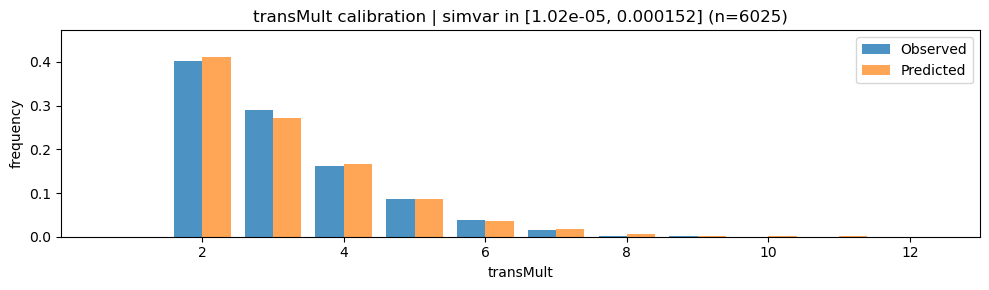

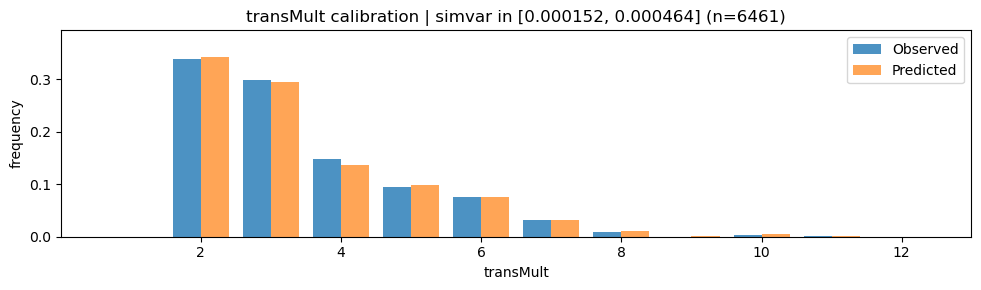

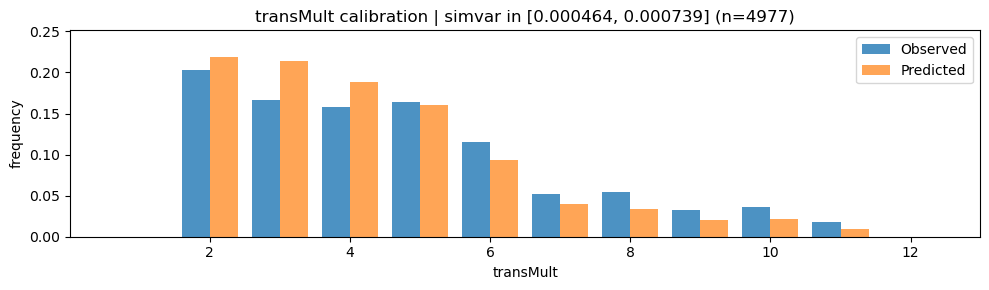

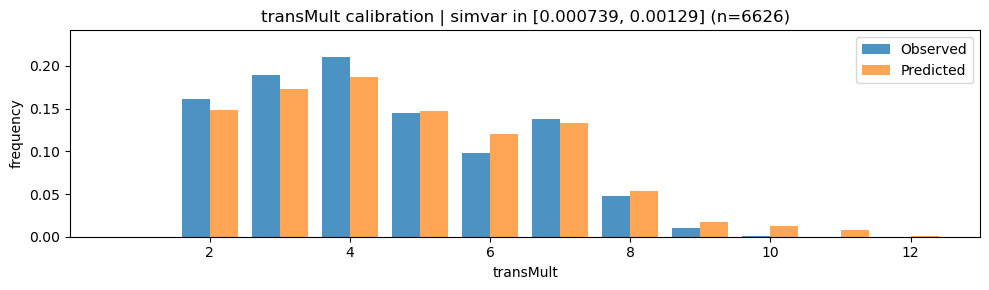

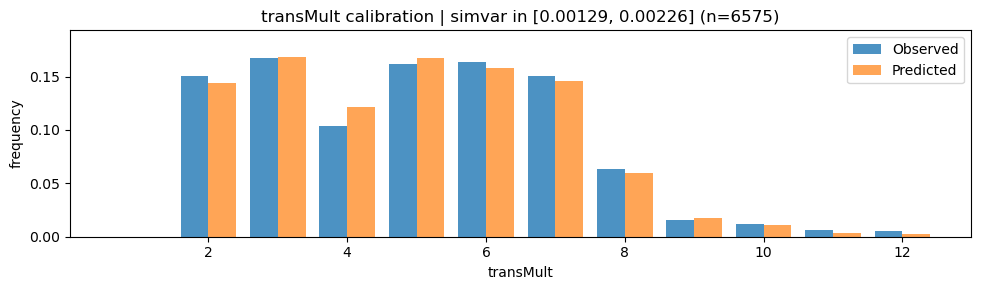

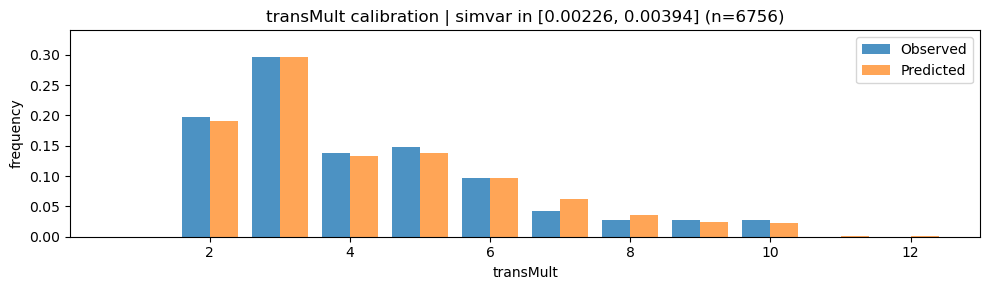

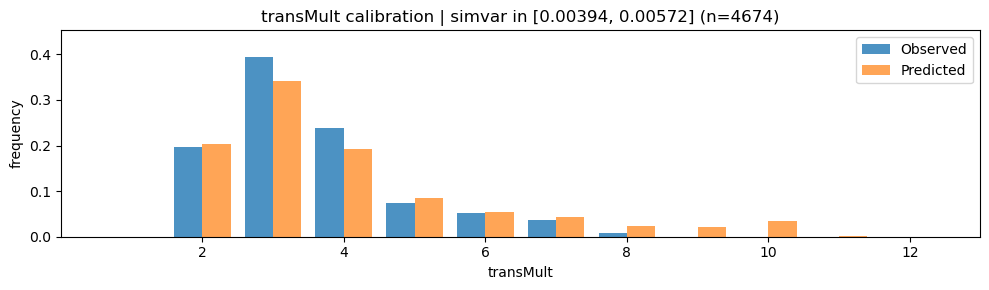

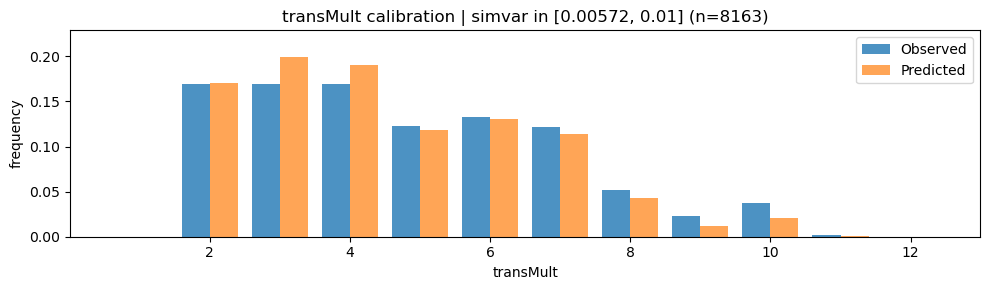

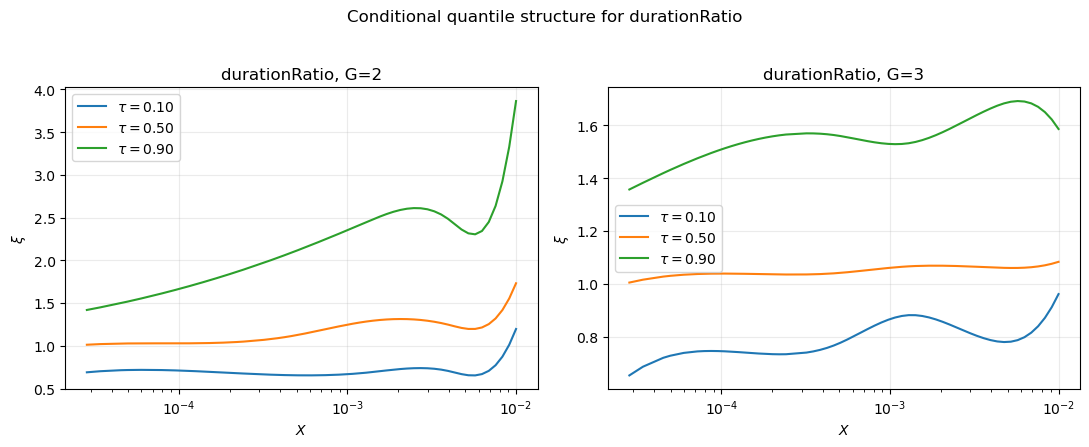

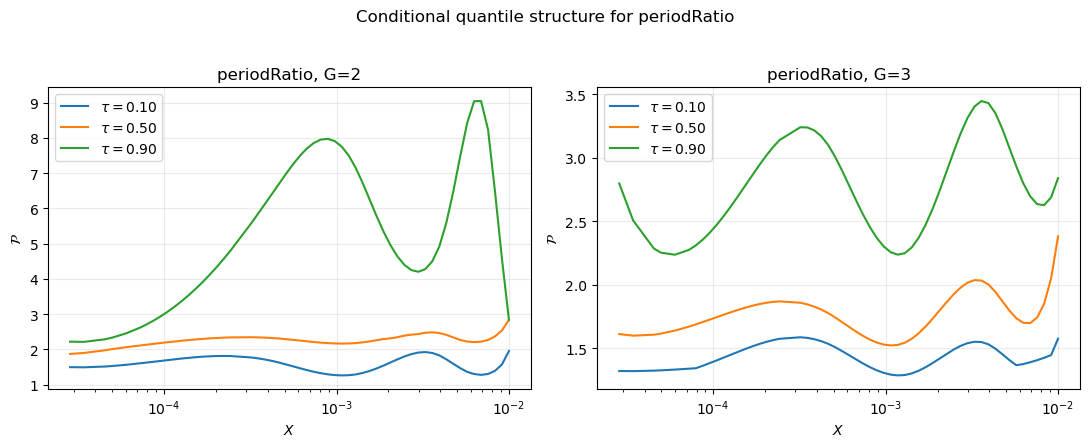

In [45]:
if RUN_FULL_ANALYSIS:
    pit_table = pd.DataFrame({
        "duration ratio xi": pit_summary(fit.oof_pit["u_dr"].to_numpy()),
        "log period ratio Z_P": pit_summary(fit.oof_pit["u_pr"].to_numpy()),
        "log Hill spacing Z_Delta": pit_summary(fit.oof_pit["u_mh"].to_numpy()),
    }).T
    display(pit_table)

    U = fit.oof_pit[["u_dr", "u_pr", "u_mh"]].to_numpy()
    display(kendall_tau_matrix(U, ["xi", "P", "Delta"]))

    plot_transmult_calibration(fit.df2, fit.trans_model, n_bins=SIMVAR_BINS_CAL)
    plot_marginal_quantile_structure(fit, Y_DR, taus_to_plot=(0.1, 0.5, 0.9))
    plot_marginal_quantile_structure(fit, Y_PR, taus_to_plot=(0.1, 0.5, 0.9))
    plt.show()

## 16. Optional explanatory figures and tail helpers

In [46]:
# =============================================================================
# FIGURE 1: Conditional marginal histograms by multiplicity group
# =============================================================================
def plot_marginal_hist_by_group(fit, n_samples=200000, seed=42):
    rng = np.random.default_rng(seed)

    df = fit.df2[[X_COL, KGRP_COL, Y_DR, Y_PR, Y_MH]].dropna().copy()
    groups = sorted(df[KGRP_COL].astype(int).unique())
    n_g = len(groups)

    # ------------------------------------------------------------
    # Emulator sampling
    # ------------------------------------------------------------
    x_all = df[X_COL].to_numpy()

    sim = simulate_structural(
        simvar_new=rng.choice(x_all, size=n_samples, replace=True),
        trans_model=fit.trans_model,
        pr_marg=fit.pr_marg,
        dr_marg=fit.dr_marg,
        mh_cond=fit.mh_cond,
        copula_drpr=fit.copula_drpr,
        tails=fit.tails,
        pitcal=fit.pitcal,
        groups=fit.tails.groups,
        n_draws=1,
        rng=rng
    )

    sim_df = pd.DataFrame({
        Y_DR: sim[Y_DR][0],
        Y_PR: sim[Y_PR][0],
        Y_MH: sim[Y_MH][0],
        KGRP_COL: make_k_group(sim["transMult"][0])
    })

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    fig, axes = plt.subplots(3, n_g, figsize=(4*n_g, 10), sharey='row', squeeze=False)

    for j, g in enumerate(groups):

        df_g = df[df[KGRP_COL].astype(int) == g]
        sim_g = sim_df[sim_df[KGRP_COL] == g]

        # ---- ξ
        ax = axes[0, j]
        bins = np.linspace(
            np.percentile(df_g[Y_DR], 1),
            np.percentile(df_g[Y_DR], 99),
            40
        )

        ax.hist(df_g[Y_DR], bins=bins, density=True, histtype="step", linewidth=2, label="Data")
        ax.hist(sim_g[Y_DR], bins=bins, density=True, histtype="step", linestyle="--", linewidth=2, label="Emulator")

        ax.set_title(f"G = {g}")
        if j == 0:
            ax.set_ylabel(r"$\xi$")

        # ---- P (log)
        ax = axes[1, j]
        log_data = np.log(df_g[Y_PR])
        bins = np.linspace(
            np.percentile(log_data, 1),
            np.percentile(log_data, 99),
            40
        )

        ax.hist(log_data, bins=bins, density=True, histtype="step", linewidth=2)
        ax.hist(np.log(sim_g[Y_PR]), bins=bins, density=True, histtype="step", linestyle="--", linewidth=2)

        if j == 0:
            ax.set_ylabel(r"$\log \mathcal{P}$")

        # ---- Δ (log)
        ax = axes[2, j]
        log_data = np.log(df_g[Y_MH])
        bins = np.linspace(
            np.percentile(log_data, 1),
            np.percentile(log_data, 99),
            40
        )

        ax.hist(log_data, bins=bins, density=True, histtype="step", linewidth=2)
        ax.hist(np.log(sim_g[Y_MH]), bins=bins, density=True, histtype="step", linestyle="--", linewidth=2)

        if j == 0:
            ax.set_ylabel(r"$\log \Delta$")

    for j in range(n_g):
        axes[2, j].set_xlabel(" ")
        # axes[2, j].set_xlabel(" ")


    axes[0, 0].legend()

    plt.tight_layout()
    return fig

In [47]:
# =============================================================================
# FIGURE: Dependence transformation (raw vs PIT space)
# =============================================================================
def plot_dependence_transformation(fit, max_points=15000, seed=42):
    rng = np.random.default_rng(seed)

    df = fit.df2[[X_COL, KGRP_COL, Y_DR, Y_PR]].dropna().copy()

    # Subsample for plotting (keeps figure clean)
    if len(df) > max_points:
        df = df.sample(max_points, random_state=seed)

    x = df[X_COL].to_numpy()
    k = df[KGRP_COL].astype(int).to_numpy()

    # ------------------------------------------------------------
    # Compute PIT values using fitted marginals
    # ------------------------------------------------------------
    Q_dr = predict_quantile_grid(fit.dr_marg, x, k)
    Q_pr = predict_quantile_grid(fit.pr_marg, x, k)

    y_dr = df[Y_DR].to_numpy()
    y_pr = df[Y_PR].to_numpy()

    u_dr = interp_cdf_from_quantiles_randomized(
        t_dr(y_dr), Q_dr, fit.dr_marg.taus, rng=rng
    )
    u_pr = interp_cdf_from_quantiles_randomized(
        t_pr(y_pr), Q_pr, fit.pr_marg.taus, rng=rng
    )

    # ------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # ---- Raw space
    axes[0].scatter(
        y_dr, y_pr,
        s=5, alpha=0.3
    )
    axes[0].set_xscale("linear")
    axes[0].set_yscale("log")
    axes[0].set_xlabel(r"$\xi$")
    axes[0].set_ylabel(r"$\mathcal{P}$")
    axes[0].set_title("Raw space")

    # ---- PIT space
    axes[1].scatter(
        u_dr, u_pr,
        s=5, alpha=0.3
    )
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    axes[1].set_xlabel(r"$U_{\xi}$")
    axes[1].set_ylabel(r"$U_{\mathcal{P}}$")
    axes[1].set_title("PIT space")

    plt.tight_layout()
    return fig

In [48]:
# =============================================================================
# FIGURE: Conditional quantiles with data overlay (clean publication version)
# =============================================================================
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullLocator

def format_log_axis(ax, axis="x"):
    locator = LogLocator(base=10.0)
    formatter = LogFormatterMathtext(base=10.0)

    if axis == "x":
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(formatter)
        ax.xaxis.set_minor_locator(NullLocator())
    else:
        ax.yaxis.set_major_locator(locator)
        ax.yaxis.set_major_formatter(formatter)
        ax.yaxis.set_minor_locator(NullLocator())

        
def plot_quantiles_by_group_clean(
    fit,
    groups=None,
    n_points_per_group=2500,
    seed=42,
    taus_to_plot=(0.1, 0.5, 0.9),
):
    rng = np.random.default_rng(seed)

    df = fit.df2[[X_COL, KGRP_COL, Y_DR, Y_PR]].dropna().copy()
    df[KGRP_COL] = df[KGRP_COL].astype(int)

    if groups is None:
        groups = sorted(df[KGRP_COL].unique().tolist())

    n_rows = len(groups)
    fig, axes = plt.subplots(
        n_rows, 2,
        figsize=(10.5, 3.6 * n_rows),
        sharex=True,
        constrained_layout=True
    )

    if n_rows == 1:
        axes = np.array([axes])

    # consistent x-grid over observed range
    x_grid = np.geomspace(
        np.percentile(df[X_COL], 1),
        np.percentile(df[X_COL], 99),
        250
    )

    # column titles only
    axes[0, 0].set_title(r"Duration ratio $\xi$", fontsize=13)
    axes[0, 1].set_title(r"Period ratio $\mathcal{P}$", fontsize=13)

    tau_styles = {
        0.1: dict(linewidth=1.8, alpha=0.95),
        0.5: dict(linewidth=2.6, alpha=1.00),
        0.9: dict(linewidth=1.8, alpha=0.95),
    }

    # y-limits by group to avoid a few extreme points dominating the panel
    ylims_dr = {}
    ylims_pr = {}
    for g in groups:
        dfg = df[df[KGRP_COL] == g]
        if len(dfg) == 0:
            continue
        ylims_dr[g] = (
            max(0, np.percentile(dfg[Y_DR], 0.5)),
            np.percentile(dfg[Y_DR], 99.5)
        )
        ylims_pr[g] = (
            np.percentile(dfg[Y_PR], 0.5),
            np.percentile(dfg[Y_PR], 99.5)
        )

    for i, g in enumerate(groups):
        dfg = df[df[KGRP_COL] == g].copy()
        if len(dfg) == 0:
            continue

        # subsample only for plotting clarity
        if len(dfg) > n_points_per_group:
            dfg = dfg.sample(n_points_per_group, random_state=seed)

        k_grid = np.full_like(x_grid, g, dtype=int)

        Q_dr = predict_quantile_grid(fit.dr_marg, x_grid, k_grid)
        Q_pr = predict_quantile_grid(fit.pr_marg, x_grid, k_grid)

        ax_dr = axes[i, 0]
        ax_pr = axes[i, 1]

        # -----------------------------
        # Scatter: lighter and cleaner
        # -----------------------------
        ax_dr.scatter(
            dfg[X_COL], dfg[Y_DR],
            s=12, alpha=0.18, rasterized=True, label="Data"
        )
        ax_pr.scatter(
            dfg[X_COL], dfg[Y_PR],
            s=12, alpha=0.18, rasterized=True
        )

        # -----------------------------
        # Quantile curves
        # -----------------------------
        for tau in taus_to_plot:
            # nearest fitted tau
            j_dr = int(np.argmin(np.abs(fit.dr_marg.taus - tau)))
            j_pr = int(np.argmin(np.abs(fit.pr_marg.taus - tau)))

            lbl = fr"$\tau={fit.dr_marg.taus[j_dr]:.1f}$" if i == 0 else None

            ax_dr.plot(
                x_grid,
                INVTR[Y_DR](Q_dr[:, j_dr]),
                label=lbl,
                **tau_styles[round(tau, 1)]
            )
            ax_pr.plot(
                x_grid,
                INVTR[Y_PR](Q_pr[:, j_pr]),
                **tau_styles[round(tau, 1)]
            )

        # -----------------------------
        # Axes formatting
        # -----------------------------
        ax_dr.set_xscale("log")
        ax_pr.set_xscale("log")
        ax_pr.set_yscale("log")

        ax_dr.set_ylim(*ylims_dr[g])
        ax_pr.set_ylim(*ylims_pr[g])

        ax_dr.grid(alpha=0.20, linewidth=0.6)
        ax_pr.grid(alpha=0.20, linewidth=0.6)

        # row label in left margin instead of title
        ax_dr.annotate(
            fr"$G={g}$",
            xy=(-0.20, 0.5),
            xycoords="axes fraction",
            ha="center",
            va="center",
            rotation=90,
            fontsize=12
        )

        # y labels
        ax_dr.set_ylabel(r"$\xi$")
        ax_pr.set_ylabel(r"$\mathcal{P}$")

    # x labels only on bottom row
    axes[-1, 0].set_xlabel(r"$X$")
    axes[-1, 1].set_xlabel(r"$X$")

    # one compact legend
    axes[0, 0].legend(
        loc="upper left",
        frameon=True,
        fontsize=10
    )

    return fig

In [49]:
# =============================================================================
# 17) Tail-event plotting helpers (direct exceedance probabilities)
# =============================================================================
from dataclasses import replace

def simulate_dr_given_group(simvar_new: np.ndarray,
                            k_grp_new: np.ndarray,
                            fit: StructuralFit,
                            use_evt: bool = True,
                            n_draws: int = 1,
                            rng=None) -> np.ndarray:
    """
    Simulate durationRatio conditional on X and fixed multiplicity group G.
    Returns array of shape (n_draws, n).
    """
    rng = rng or np.random.default_rng()
    simvar_new = np.asarray(simvar_new).reshape(-1)
    k_grp_new = np.asarray(k_grp_new).astype(int).reshape(-1)
    n = simvar_new.size

    Q_dr = predict_quantile_grid(fit.dr_marg, simvar_new, k_grp_new)
    out = np.empty((n_draws, n), dtype=float)

    for d in range(n_draws):
        for i in range(n):
            x_i = float(simvar_new[i])
            kg_i = int(k_grp_new[i])

            # draw dependent calibrated PITs; use DR component only
            u2_cal = fit.copula_drpr.sampler_for(x_i, kg_i)(1, rng=rng)[:, 0]
            u_dr_cal = float(u2_cal[0])

            # invert PIT calibration
            u_dr = fit.pitcal.inverse(u_dr_cal, Y_DR, x_i, kg_i)

            # map group to tail index
            g_idx = 0
            for gi, (lo, hi) in enumerate(fit.tails.groups):
                if lo <= kg_i <= hi:
                    g_idx = gi
                    break

            if use_evt:
                xi_dr, beta_dr = fit.tails.params[(Y_DR, g_idx)]
                dr_t = _sample_from_qgrid_evt(
                    u_dr, Q_dr[i, :], fit.dr_marg.taus, fit.tails.tau0, xi_dr, beta_dr
                )
            else:
                dr_t = sample_from_qgrid_no_evt(u_dr, Q_dr[i, :], fit.dr_marg.taus)

            out[d, i] = float(it_dr(dr_t))

    return out


def make_tail_rate_table(df_holdout: pd.DataFrame,
                         fit_evt: StructuralFit,
                         threshold: Optional[float] = None,
                         threshold_quantile: float = 0.975,
                         groups_to_plot=(2, 3),
                         n_bins: int = 8,
                         n_draws_per_x: int = 200,
                         min_bin_n: int = 40,
                         rng_seed: int = 2026) -> Tuple[pd.DataFrame, float]:
    """
    Build a table of empirical and emulator-estimated exceedance probabilities:
        P(durationRatio > threshold | X, G)

    If threshold is None, it is chosen as the threshold_quantile quantile of
    durationRatio within the held-out data restricted to groups_to_plot.
    """
    rng = np.random.default_rng(rng_seed)

    dfi = df_holdout[[X_COL, KGRP_COL, Y_DR]].dropna().copy()
    dfi[KGRP_COL] = dfi[KGRP_COL].astype(int)
    dfi = dfi[dfi[KGRP_COL].isin(groups_to_plot)].copy()

    if threshold is None:
        threshold = float(
            np.quantile(
                dfi.loc[dfi[KGRP_COL].isin(groups_to_plot), Y_DR].to_numpy(),
                threshold_quantile
            )
        )

    rows = []

    for g in groups_to_plot:
        dg = dfi[dfi[KGRP_COL] == g].copy()
        if len(dg) == 0:
            continue

        x = dg[X_COL].to_numpy()
        y = dg[Y_DR].to_numpy()

        # quantile bins in X
        edges = np.quantile(x, np.linspace(0, 1, n_bins + 1))
        edges = np.unique(edges)
        if len(edges) < 3:
            continue

        for b in range(len(edges) - 1):
            lo, hi = edges[b], edges[b + 1]
            if b == len(edges) - 2:
                m = (x >= lo) & (x <= hi)
            else:
                m = (x >= lo) & (x < hi)

            if m.sum() < min_bin_n:
                continue

            x_bin = x[m]
            y_bin = y[m]
            n_bin = len(x_bin)

            # empirical exceedance
            emp = float(np.mean(y_bin > threshold))
            emp_se = float(np.sqrt(max(emp * (1 - emp) / n_bin, 0.0)))

            # emulator exceedance, baseline
            k_arr = np.full(n_bin, g, dtype=int)
            sim_base = simulate_dr_given_group(
                simvar_new=x_bin,
                k_grp_new=k_arr,
                fit=fit_evt,
                use_evt=False,
                n_draws=n_draws_per_x,
                rng=rng
            )
            base = float(np.mean(sim_base > threshold))

            # emulator exceedance, tail-aware
            sim_evt = simulate_dr_given_group(
                simvar_new=x_bin,
                k_grp_new=k_arr,
                fit=fit_evt,
                use_evt=True,
                n_draws=n_draws_per_x,
                rng=rng
            )
            evt = float(np.mean(sim_evt > threshold))

            # geometric bin center for log-x plotting
            x_mid = float(np.exp(np.mean(np.log(x_bin))))

            rows.append({
                "group": g,
                "bin": b,
                "x_left": float(lo),
                "x_right": float(hi),
                "x_mid": x_mid,
                "n": int(n_bin),
                "empirical": emp,
                "empirical_se": emp_se,
                "baseline": base,
                "tail_aware": evt,
            })

    out = pd.DataFrame(rows, columns=["group", "bin", "x_left", "x_right", "x_mid", "n", "empirical", "empirical_se", "baseline", "tail_aware"]).sort_values(["group", "x_mid"]).reset_index(drop=True)
    return out, threshold


def plot_tail_event_rates(df_holdout: pd.DataFrame,
                          fit_evt: StructuralFit,
                          threshold: Optional[float] = None,
                          threshold_quantile: float = 0.975,
                          groups_to_plot=(2, 3),
                          n_bins: int = 8,
                          n_draws_per_x: int = 200,
                          min_bin_n: int = 40,
                          figsize=(11, 4.5),
                          rng_seed: int = 2026):
    """
    Plot direct tail-event rates:
        empirical, baseline emulator, tail-aware emulator
    """
    tail_df, threshold_used = make_tail_rate_table(
        df_holdout=df_holdout,
        fit_evt=fit_evt,
        threshold=threshold,
        threshold_quantile=threshold_quantile,
        groups_to_plot=groups_to_plot,
        n_bins=n_bins,
        n_draws_per_x=n_draws_per_x,
        min_bin_n=min_bin_n,
        rng_seed=rng_seed
    )

    fig, axes = plt.subplots(1, len(groups_to_plot), figsize=figsize, sharey=True)
    if len(groups_to_plot) == 1:
        axes = [axes]

    for ax, g in zip(axes, groups_to_plot):
        dfg = tail_df[tail_df["group"] == g].copy()
        if len(dfg) == 0:
            ax.set_visible(False)
            continue

        ax.errorbar(
            dfg["x_mid"], dfg["empirical"], yerr=1.96 * dfg["empirical_se"],
            fmt="o", capsize=3, label="Held-out simulations"
        )
        ax.plot(
            dfg["x_mid"], dfg["baseline"],
            linestyle="--", linewidth=2, label="Baseline emulator"
        )
        ax.plot(
            dfg["x_mid"], dfg["tail_aware"],
            linewidth=2.5, label="Tail-aware emulator"
        )

        ax.set_xscale("log")
        ax.set_xlabel(PAPER_LABELS[X_COL])
        ax.set_title(f"$G={g}$")
        ax.grid(alpha=0.25)

    axes[0].set_ylabel(rf"$\Pr(\xi > {threshold_used:.2f}\mid X, G)$")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 1.04))

    fig.suptitle(
        rf"Tail-event rates for duration ratio: $\Pr(\xi > {threshold_used:.2f}\mid X, G)$",
        y=1.10
    )
    fig.tight_layout()
    return fig, tail_df, threshold_used

The following optional calls use the fit and training data for exploratory figures. They are not independent held-out validation. The tail helpers above require a separate held-out dataframe and a fit trained without those observations.

The histogram comparison can be expensive because it samples the full emulator. It is disabled by default. Histogram curves are normalized within the displayed range; use full-support bins if total tail mass is the quantity of interest.


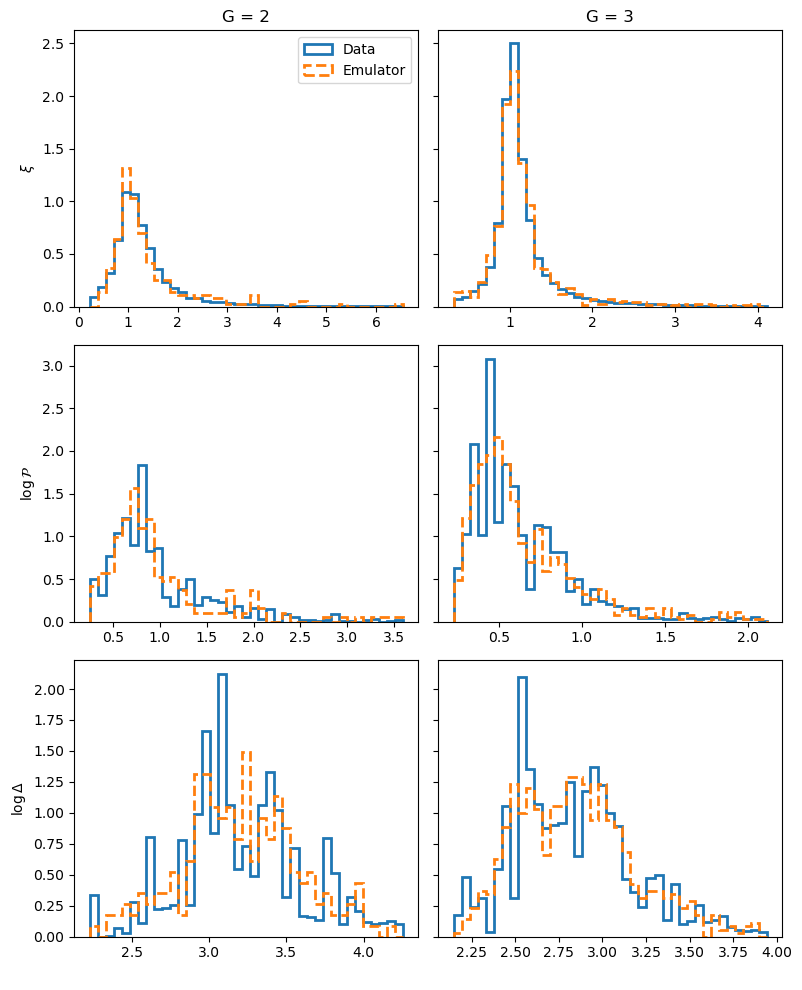

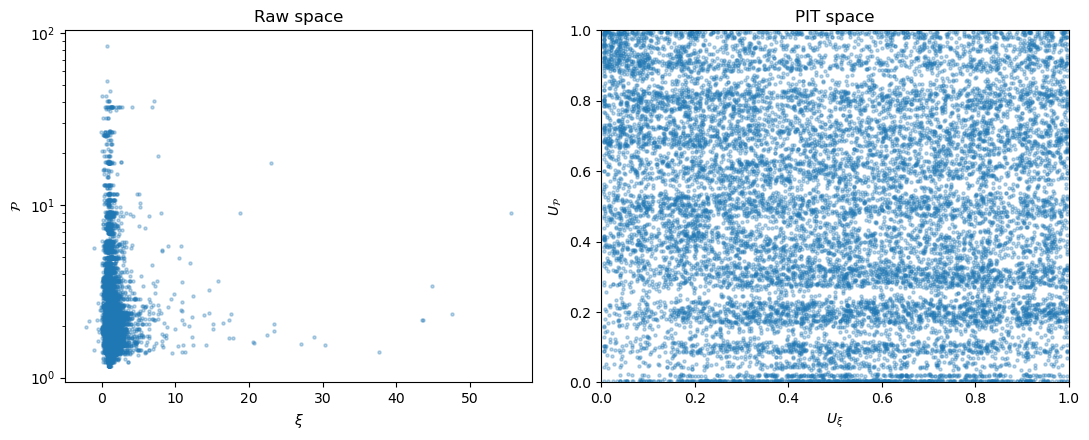

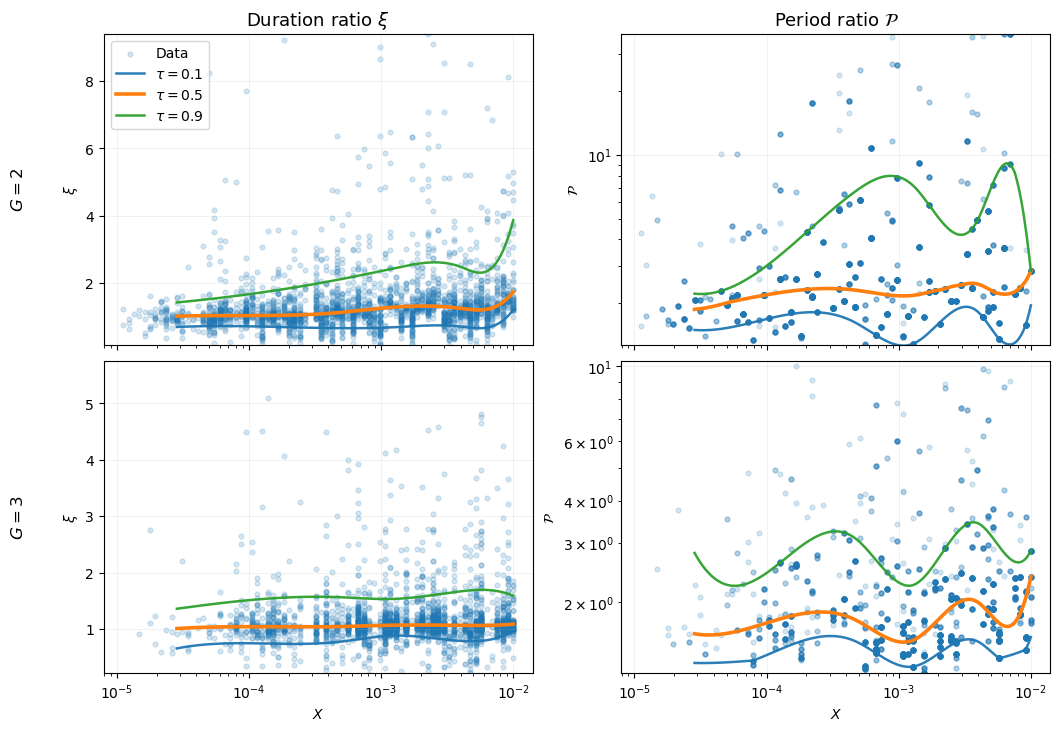

In [50]:
# RUN_OPTIONAL_FIGURES = True
if RUN_FULL_ANALYSIS and RUN_OPTIONAL_FIGURES:
    plot_marginal_hist_by_group(fit, n_samples=1000, seed=RANDOM_SEED)
    plot_dependence_transformation(fit, seed=RANDOM_SEED)
    plot_quantiles_by_group_clean(fit, seed=RANDOM_SEED)
    plt.show()


## 17. Generate conditional realizations

All sampling code is above; no saved model is loaded. Array rows are repeated draws and columns are the supplied input values. Increase `N_DEMO_DRAWS` and `N_DEMO_INPUTS` in the data/settings cell when you want a larger output.

The supplied sampler returns one representative pair summary for each sampled multiplicity, rather than an ordered catalog of all M-1 neighboring pairs. The handling of zero/single detections is one of the review items below. Draws represent stochastic outcome variation at fixed fitted parameters, not uncertainty in those parameters.


In [51]:
if RUN_FULL_ANALYSIS:
    x_demo = np.geomspace(df[X_COL].quantile(0.05), df[X_COL].quantile(0.95), N_DEMO_INPUTS)
    draws = simulate_structural(
        simvar_new=x_demo,
        trans_model=fit.trans_model,
        pr_marg=fit.pr_marg,
        dr_marg=fit.dr_marg,
        mh_cond=fit.mh_cond,
        copula_drpr=fit.copula_drpr,
        tails=fit.tails,
        pitcal=fit.pitcal,
        groups=fit.tails.groups,
        n_draws=N_DEMO_DRAWS,
        rng=np.random.default_rng(RANDOM_SEED),
    )
    print("Generated", draws[Y_DR].shape[0], "conditional realizations at", len(x_demo), "input values.")

Generated 10 conditional realizations at 10 input values.
